# Exercise description

Implement two methods adapted to [problem description](data/dataset-description.md), based on both the extended version of the nearest neighbor heuristic and the greedy cycle heuristic:
- Greedy 2-regret heuristics.
- Greedy heuristics with a weighted sum criterion - 2-regret + best change of the objective function. By default use equal weights but you can also experiment with other values.

The structure of the report should be the same as previously. In the summary of results please include results of the previous methods.

For reference, the Lab 1 methods are kept in the comparison:
- Random solution
- Nearest neighbor considering adding the node only at the end of the current path
- Nearest neighbor considering adding the node at all possible position, i.e. at the end, at the beginning, or at any place inside the current path
- Greedy cycle

The report should contain:
- Description of the problem
- Pseudocode of all implemented algorithms
- Results of a computational experiment: for each instance and method min, max and average value of the objective function.
- Weight sensitivity of the weighted-sum criterion.
- 2D visualization of the best solution for each instance and method. Cost of nodes should be presented e.g. by a color, greyscale, or size.
- The best solutions for each instance and method presented as a list of nodes indices (starting from 0).
- Information whether the best solutions have been checked with the solution checker.
- (Link to) the source code
- Conclusions

## Helpers and parameters

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('data')
INSTANCES = ['TSPA', 'TSPB']
RNG_SEED = 0
NUM_OF_RANDOM_RUNS = 200

WEIGHT_CONFIGS = [
    (1.0, 1.0),  
    (1.0, 0.5),
    (0.5, 1.0),
]

def load_instance(name: str):
    _p = DATA / f'{name}.csv'
    with open(_p) as _fh:
        _first = _fh.readline()
    _skip = 1 if any(c.isalpha() for c in _first) else 0
    d = np.loadtxt(_p, delimiter=';', skiprows=_skip, dtype=int)
    xy, costs = d[:, :2], d[:, 2]
    diff = xy[:, None, :] - xy[None, :, :]
    dist = np.rint(np.sqrt((diff ** 2).sum(axis=-1))).astype(int)
    n = len(costs)
    k = (n + 1) // 2
    return {'name': name, 'xy': xy, 'costs': costs, 'dist': dist, 'n': n, 'k': k}

problems = {name: load_instance(name) for name in INSTANCES}

def compute_cost(tour, dist: np.ndarray, costs: np.ndarray) -> int:
    t = np.asarray(tour, dtype=int)
    return int(dist[t, np.roll(t, -1)].sum() + costs[t].sum())

def check_solution(tour, n: int, k: int) -> tuple[bool, str]:
    """Used at the end to check solution's correctness"""
    t = list(tour)
    if len(t) != k:
        return False, f'length {len(t)} != k={k}'
    if len(set(t)) != k:
        return False, 'duplicate nodes'
    if any(not isinstance(v, (int, np.integer)) or v < 0 or v >= n for v in t):
        return False, 'index out of range'
    return True, 'ok'

problem = problems['TSPA']
t = list(range(problem['k']))

## Search method definitions

In [2]:
def random_tour(n: int, k: int, rng: np.random.Generator) -> list[int]:
    """Browse the graph at random"""
    selected = rng.choice(n, size=k, replace=False)
    rng.shuffle(selected)
    return [int(v) for v in selected]

def nearest_neighbor_at_end(start: int, distances: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    """Insert nearest neighbor at the end of path

    :param k: number of nearest neighbors to take into account
    """
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        last = tour[-1]
        cand = np.flatnonzero(~used)
        vals = distances[last, cand] + costs[cand]
        nxt = int(cand[int(np.argmin(vals))])
        tour.append(nxt); used[nxt] = True
    return tour

def nearest_neighbor_anywhere(start: int, distances: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    """Insert nearest neighbor in any place in the current path

    :param k: number of nearest neighbors to take into account
    """
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int); m = len(t)
        D = distances[np.ix_(cand, t)]
        best = D[:, 0].astype(np.int64).copy()
        pos = np.zeros(len(cand), dtype=int)
        d_end = D[:, -1]
        upd = d_end < best; best[upd] = d_end[upd]; pos[upd] = m
        if m > 1:
            seg = distances[t[:-1], t[1:]]
            ins = D[:, :-1] + D[:, 1:] - seg[None, :]
            j = np.argmin(ins, axis=1)
            v = ins[np.arange(len(cand)), j]
            upd = v < best; best[upd] = v[upd]; pos[upd] = j[upd] + 1
        best = best + costs[cand]
        i = int(np.argmin(best))
        tour.insert(int(pos[i]), int(cand[i])); used[cand[i]] = True
    return tour

def greedy_cycle(start: int, dist: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    """Greedily form a cycle

    :param k: number of nearest neighbors to take into account
    """
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int); m = len(t)
        if m == 1:
            delta = 2 * dist[int(start), cand] + costs[cand]
            i = int(np.argmin(delta))
            tour.append(int(cand[i])); used[cand[i]] = True
            continue
        nxt = np.roll(t, -1)
        seg = dist[t, nxt]                    # (m,)
        ins = dist[np.ix_(cand, t)] + dist[np.ix_(cand, nxt)] - seg[None, :]  # (C, m)
        j = np.argmin(ins, axis=1)
        v = ins[np.arange(len(cand)), j] + costs[cand]
        i = int(np.argmin(v))
        tour.insert(int(j[i]) + 1, int(cand[i])); used[cand[i]] = True
    return tour

def _path_insertion_deltas(cand: np.ndarray, t: np.ndarray, distances: np.ndarray) -> np.ndarray:
    """Insertion deltas of every candidate over all path positions (start, inside, end)"""
    m = len(t)
    D = distances[np.ix_(cand, t)]
    deltas = np.empty((len(cand), m + 1), dtype=np.int64)
    deltas[:, 0] = D[:, 0]
    deltas[:, m] = D[:, -1]
    if m > 1:
        seg = distances[t[:-1], t[1:]]
        deltas[:, 1:m] = D[:, :-1] + D[:, 1:] - seg[None, :]
    return deltas

def _cycle_insertion_deltas(cand: np.ndarray, t: np.ndarray, dist: np.ndarray) -> np.ndarray:
    """Insertion deltas of every candidate on every cycle edge"""
    if len(t) == 1:
        return (2 * dist[int(t[0]), cand])[:, None]
    nxt = np.roll(t, -1)
    seg = dist[t, nxt]
    return dist[np.ix_(cand, t)] + dist[np.ix_(cand, nxt)] - seg[None, :]

def _choose_candidate(deltas: np.ndarray, costs_cand: np.ndarray, mode: str,
                      w_regret: float, w_cost: float) -> tuple[int, int]:
    """Pick candidate + position by regret, or by the weighted regret/cost score"""
    d = deltas + costs_cand[:, None]
    if d.shape[1] == 1:
        best = d[:, 0]
        regret = np.zeros(len(costs_cand), dtype=np.float64)
        best_pos = np.zeros(len(costs_cand), dtype=int)
    else:
        best_pos = np.argmin(d, axis=1)
        best = d[np.arange(len(d)), best_pos]
        part = np.argpartition(d, 1, axis=1)[:, :2]
        v0 = d[np.arange(len(d)), part[:, 0]]
        v1 = d[np.arange(len(d)), part[:, 1]]
        second = np.maximum(v0, v1)
        regret = (second - best).astype(np.float64)

    if mode == 'regret':
        i = int(np.lexsort((best, -regret))[0])
    else:
        score = w_regret * regret - w_cost * best.astype(np.float64)
        i = int(np.lexsort((best, -score))[0])
    return i, int(best_pos[i])

def greedy_2regret_nn(start: int, distances: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    """Greedy 2-regret using path (extended NN) insertion"""
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int)
        i, pos = _choose_candidate(_path_insertion_deltas(cand, t, distances), costs[cand], 'regret', 1.0, 1.0)
        tour.insert(pos, int(cand[i])); used[cand[i]] = True
    return tour

def greedy_2regret_cycle(start: int, dist: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    """Greedy 2-regret using cycle insertion"""
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int)
        i, pos = _choose_candidate(_cycle_insertion_deltas(cand, t, dist), costs[cand], 'regret', 1.0, 1.0)
        if len(tour) == 1:
            tour.append(int(cand[i]))
        else:
            tour.insert(pos + 1, int(cand[i]))
        used[cand[i]] = True
    return tour

def greedy_weighted_nn(start: int, distances: np.ndarray, costs: np.ndarray, k: int,
                       w_regret: float = 1.0, w_cost: float = 1.0) -> list[int]:
    """Weighted 2-regret + best change using path (extended NN) insertion"""
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int)
        i, pos = _choose_candidate(
            _path_insertion_deltas(cand, t, distances), costs[cand], 'weighted', w_regret, w_cost)
        tour.insert(pos, int(cand[i])); used[cand[i]] = True
    return tour

def greedy_weighted_cycle(start: int, dist: np.ndarray, costs: np.ndarray, k: int,
                          w_regret: float = 1.0, w_cost: float = 1.0) -> list[int]:
    """Weighted 2-regret + best change using cycle insertion"""
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int)
        i, pos = _choose_candidate(
            _cycle_insertion_deltas(cand, t, dist), costs[cand], 'weighted', w_regret, w_cost)
        if len(tour) == 1:
            tour.append(int(cand[i]))
        else:
            tour.insert(pos + 1, int(cand[i]))
        used[cand[i]] = True
    return tour

## Compare the methods

In [3]:
rng = np.random.default_rng(RNG_SEED)
for fn in (lambda s, D, C, k: random_tour(problem['n'], problem['k'], rng), nearest_neighbor_at_end, nearest_neighbor_anywhere, greedy_cycle, greedy_2regret_nn, greedy_2regret_cycle, greedy_weighted_nn, greedy_weighted_cycle):
    tt = fn(0, problem['dist'], problem['costs'], problem['k'])
    print(fn.__name__ if hasattr(fn, '__name__') else fn, compute_cost(tt, problem['dist'], problem['costs']), check_solution(tt, problem['n'], problem['k']))

<lambda> 252162 (True, 'ok')
nearest_neighbor_at_end 88750 (True, 'ok')
nearest_neighbor_anywhere 74371 (True, 'ok')
greedy_cycle 73758 (True, 'ok')
greedy_2regret_nn 122903 (True, 'ok')
greedy_2regret_cycle 118099 (True, 'ok')
greedy_weighted_nn 76719 (True, 'ok')
greedy_weighted_cycle 73240 (True, 'ok')


In [4]:
results, best_tours, timings = {}, {}, {}
METHODS = [
    ('nearest_neighbor_at_end', nearest_neighbor_at_end),
    ('nearest_neighbor_anywhere', nearest_neighbor_anywhere),
    ('greedy_cycle', greedy_cycle),
    ('greedy_2regret_nn', greedy_2regret_nn),
    ('greedy_2regret_cycle', greedy_2regret_cycle),
    ('greedy_weighted_nn', greedy_weighted_nn),
    ('greedy_weighted_cycle', greedy_weighted_cycle),
]
METHOD_ORDER = ['random'] + [m for m, _ in METHODS]
rng = np.random.default_rng(RNG_SEED)
for name in INSTANCES:
    pr = problems[name]
    n, k, dist, costs = pr['n'], pr['k'], pr['dist'], pr['costs']
    results[name], best_tours[name], timings[name] = {}, {}, {}
    t0 = time.perf_counter()
    tours = [random_tour(n, k, rng) for _ in range(NUM_OF_RANDOM_RUNS)]
    vals = np.array([compute_cost(t, dist, costs) for t in tours])
    results[name]['random'] = vals
    best_tours[name]['random'] = tours[int(np.argmin(vals))]
    timings[name]['random'] = time.perf_counter() - t0
    for mname, fn in METHODS:
        t0 = time.perf_counter()
        tours = [fn(s, dist, costs, k) for s in range(n)]
        vals = np.array([compute_cost(t, dist, costs) for t in tours])
        results[name][mname] = vals
        best_tours[name][mname] = tours[int(np.argmin(vals))]
        timings[name][mname] = time.perf_counter() - t0
        print(f'{name}/{mname}: min_cost={vals.min()} max_cost={vals.max()} mean_cost={vals.mean():.1f} ({timings[name][mname]:.1f}s)')
    print(f"{name}/random: min={results[name]['random'].min()} max={results[name]['random'].max()} mean={results[name]['random'].mean():.1f} ({timings[name]['random']:.1f}s)")

TSPA/nearest_neighbor_at_end: min_cost=84362 max_cost=90075 mean_cost=87476.6 (0.1s)
TSPA/nearest_neighbor_anywhere: min_cost=72328 max_cost=77022 mean_cost=74347.0 (1.0s)
TSPA/greedy_cycle: min_cost=72590 max_cost=75281 mean_cost=73793.4 (1.4s)
TSPA/greedy_2regret_nn: min_cost=110950 max_cost=135771 mean_cost=121360.3 (2.8s)
TSPA/greedy_2regret_cycle: min_cost=112806 max_cost=128089 mean_cost=120378.8 (3.1s)
TSPA/greedy_weighted_nn: min_cost=72419 max_cost=78504 mean_cost=75549.4 (2.8s)
TSPA/greedy_weighted_cycle: min_cost=72011 max_cost=75532 mean_cost=73353.5 (3.1s)
TSPA/random: min=237157 max=289146 mean=263626.5 (0.0s)
TSPB/nearest_neighbor_at_end: min_cost=56007 max_cost=63166 mean_cost=59397.3 (0.1s)
TSPB/nearest_neighbor_anywhere: min_cost=52915 max_cost=66164 mean_cost=59480.3 (1.0s)
TSPB/greedy_cycle: min_cost=55655 max_cost=63734 mean_cost=59649.9 (1.4s)
TSPB/greedy_2regret_nn: min_cost=68761 max_cost=79756 mean_cost=73649.8 (2.7s)
TSPB/greedy_2regret_cycle: min_cost=68150 m

In [5]:
weight_results = []
for name in INSTANCES:
    pr = problems[name]
    n, k, dist, costs = pr['n'], pr['k'], pr['dist'], pr['costs']
    for w_r, w_c in WEIGHT_CONFIGS:
        for base, fn in [('nn', greedy_weighted_nn), ('cycle', greedy_weighted_cycle)]:
            tours = [fn(s, dist, costs, k, w_regret=w_r, w_cost=w_c) for s in range(n)]
            vals = np.array([compute_cost(t, dist, costs) for t in tours])
            weight_results.append({
                'instance': name,
                'base': base,
                'w_regret': w_r,
                'w_cost': w_c,
                'min_cost': int(vals.min()),
                'max_cost': int(vals.max()),
                'mean_cost': float(vals.mean()),
            })
            print(f'{name}/weighted_{base} w=({w_r},{w_c}): min={vals.min()} mean={vals.mean():.1f}')

weight_summary = pd.DataFrame(weight_results).set_index(['instance', 'base', 'w_regret', 'w_cost'])
weight_summary

TSPA/weighted_nn w=(1.0,1.0): min=72419 mean=75549.4
TSPA/weighted_cycle w=(1.0,1.0): min=72011 mean=73353.5
TSPA/weighted_nn w=(1.0,0.5): min=73614 mean=76408.1
TSPA/weighted_cycle w=(1.0,0.5): min=72575 mean=74277.2
TSPA/weighted_nn w=(0.5,1.0): min=72134 mean=75279.7
TSPA/weighted_cycle w=(0.5,1.0): min=72049 mean=73189.0
TSPB/weighted_nn w=(1.0,1.0): min=50485 mean=55698.9
TSPB/weighted_cycle w=(1.0,1.0): min=52731 mean=57863.3
TSPB/weighted_nn w=(1.0,0.5): min=51286 mean=54710.1
TSPB/weighted_cycle w=(1.0,0.5): min=52788 mean=59659.1
TSPB/weighted_nn w=(0.5,1.0): min=52302 mean=56150.8
TSPB/weighted_cycle w=(0.5,1.0): min=52099 mean=55714.3


min_cost  max_cost  mean_cost
instance base  w_regret w_cost                               
TSPA     nn    1.0      1.0        72419     78504  75549.360
         cycle 1.0      1.0        72011     75532  73353.485
         nn    1.0      0.5        73614     79873  76408.125
         cycle 1.0      0.5        72575     76095  74277.180
         nn    0.5      1.0        72134     78210  75279.725
         cycle 0.5      1.0        72049     75274  73189.010
TSPB     nn    1.0      1.0        50485     61406  55698.940
         cycle 1.0      1.0        52731     63370  57863.290
         nn    1.0      0.5        51286     60794  54710.060
         cycle 1.0      0.5        52788     63809  59659.115
         nn    0.5      1.0        52302     63489  56150.755
         cycle 0.5      1.0        52099     62556  55714.280

In [6]:
rows = []
for name in INSTANCES:
    for mname in METHOD_ORDER:
        v = results[name][mname]
        rows.append({'instance': name, 'method': mname, 'min_cost': int(v.min()),
                       'max_cost': int(v.max()), 'mean_cost': float(v.mean()),
                       'time_s': round(timings[name][mname], 2)})
summary = pd.DataFrame(rows).set_index(['instance', 'method'])
summary

min_cost  max_cost   mean_cost  time_s
instance method                                                           
TSPA     random                       237157    289146  263626.450    0.00
         nearest_neighbor_at_end       84362     90075   87476.630    0.07
         nearest_neighbor_anywhere     72328     77022   74346.965    1.04
         greedy_cycle                  72590     75281   73793.405    1.40
         greedy_2regret_nn            110950    135771  121360.290    2.76
         greedy_2regret_cycle         112806    128089  120378.765    3.12
         greedy_weighted_nn            72419     78504   75549.360    2.78
         greedy_weighted_cycle         72011     75532   73353.485    3.14
TSPB     random                       188874    232618  207052.815    0.00
         nearest_neighbor_at_end       56007     63166   59397.335    0.07
         nearest_neighbor_anywhere     52915     66164   59480.275    1.03
         greedy_cycle                  55655     63734   59649.910    1.39
         greedy_2regret_nn             68761     79756   73649.840    2.72
         greedy_2regret_cycle          68150     77274   72484.840    3.13
         greedy_weighted_nn            50485     61406   55698.940    2.73
         greedy_weighted_cycle         52731     63370   57863.290    3.14

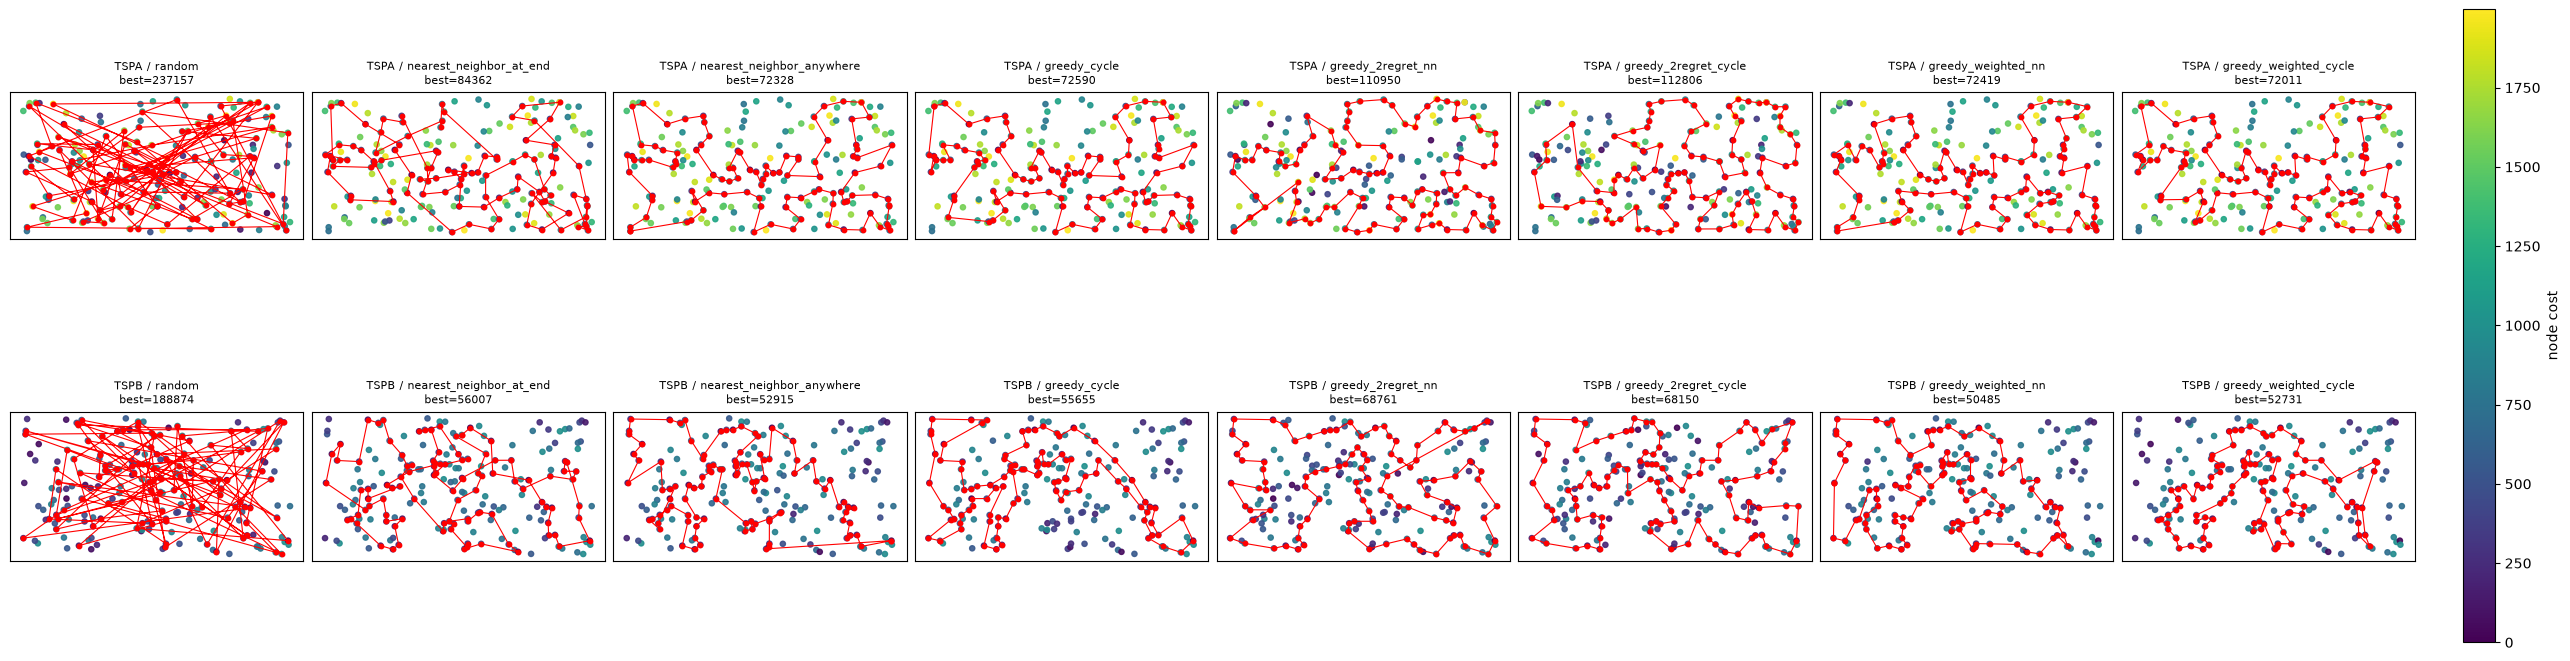

In [7]:
from matplotlib.colors import Normalize

PLOT_METHODS = METHOD_ORDER
all_costs = np.concatenate([problems[n]['costs'] for n in INSTANCES])
norm = Normalize(vmin=int(all_costs.min()), vmax=int(all_costs.max()))
sm = plt.cm.ScalarMappable(norm=norm, cmap='viridis')

with plt.style.context('default'):
    fig, axes = plt.subplots(len(INSTANCES), len(PLOT_METHODS), figsize=(3.2 * len(PLOT_METHODS), 6.5),
                             constrained_layout=True)
    fig.patch.set_facecolor('white')
    if len(INSTANCES) == 1:
        axes = np.array([axes])
    for i, name in enumerate(INSTANCES):
        pr = problems[name]
        xy, costs = pr['xy'], pr['costs']
        for j, mname in enumerate(PLOT_METHODS):
            ax = axes[i, j]
            ax.set_facecolor('white')
            tour = best_tours[name][mname]
            t = np.asarray(tour, dtype=int)
            c = compute_cost(t, pr['dist'], pr['costs'])
            ax.scatter(xy[:, 0], xy[:, 1], c=costs, cmap='viridis', norm=norm, s=14, alpha=0.9, zorder=1)
            path = xy[np.append(t, t[0])]
            ax.plot(path[:, 0], path[:, 1], 'r-', lw=0.8, zorder=3)
            ax.scatter(path[:, 0], path[:, 1], c='red', s=10, zorder=4)
            ax.set_title(f'{name} / {mname}\nbest={c}', fontsize=8)
            ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sm, ax=axes, location='right', fraction=0.015, pad=0.02, label='node cost')
    plt.show()

## Final paths

In [8]:
for name in INSTANCES:
    pr = problems[name]
    print(f'=== {name} (n={pr["n"]}, k={pr["k"]}) ===')
    for mname in METHOD_ORDER:
        tour = best_tours[name][mname]
        cost = compute_cost(tour, pr['dist'], pr['costs'])
        print(f'{mname}:\ncost={cost}\nnode indices:', end=" ")
        print(tour)
        print()

=== TSPA (n=200, k=100) ===
random:
cost=237157
node indices: [12, 18, 10, 187, 168, 160, 183, 171, 99, 80, 102, 144, 172, 88, 22, 135, 4, 92, 188, 59, 62, 86, 89, 151, 50, 35, 46, 190, 123, 111, 129, 198, 152, 25, 15, 98, 74, 126, 79, 84, 31, 191, 43, 20, 23, 28, 87, 109, 186, 78, 136, 29, 145, 56, 139, 162, 130, 9, 179, 189, 27, 195, 34, 142, 3, 181, 70, 149, 39, 150, 45, 167, 108, 7, 133, 105, 124, 184, 19, 52, 51, 65, 76, 82, 132, 166, 196, 42, 5, 21, 153, 66, 36, 97, 119, 161, 180, 158, 67, 17]

nearest_neighbor_at_end:
cost=84362
node indices: [54, 9, 33, 36, 177, 67, 144, 53, 135, 58, 134, 176, 174, 106, 89, 107, 57, 182, 151, 93, 50, 3, 1, 164, 178, 29, 136, 186, 184, 47, 159, 130, 153, 78, 88, 193, 170, 146, 75, 64, 150, 42, 113, 43, 85, 142, 8, 131, 84, 158, 192, 181, 114, 141, 180, 132, 76, 80, 48, 31, 63, 149, 168, 97, 127, 187, 30, 123, 152, 108, 60, 116, 49, 11, 119, 160, 83, 90, 51, 16, 35, 87, 45, 140, 52, 179, 185, 28, 102, 156, 157, 71, 91, 38, 100, 4, 112, 139, 115, 

In [9]:
from pathlib import Path

# Save every best solution as paste-ready node ids:
#  - solutions/lab2_{instance}_{method}_ids.csv -> one node id per line, no header
#    (paste into column F, rows 3-102 of Solution checker.xlsx)
OUT = Path('solutions')
OUT.mkdir(exist_ok=True)
for _name in INSTANCES:
    for _m in METHOD_ORDER:
        _tour = [int(_v) for _v in best_tours[_name][_m]]
        with open(OUT / f'lab2_{_name}_{_m}_ids.csv', 'w') as _f:
            for _idx in _tour:
                _f.write(f'{_idx}\n')
        print(f'saved {OUT / ("lab2_" + _name + "_" + _m + "_ids.csv")}')

saved solutions\lab2_TSPA_random_ids.csv
saved solutions\lab2_TSPA_nearest_neighbor_at_end_ids.csv
saved solutions\lab2_TSPA_nearest_neighbor_anywhere_ids.csv
saved solutions\lab2_TSPA_greedy_cycle_ids.csv
saved solutions\lab2_TSPA_greedy_2regret_nn_ids.csv
saved solutions\lab2_TSPA_greedy_2regret_cycle_ids.csv
saved solutions\lab2_TSPA_greedy_weighted_nn_ids.csv
saved solutions\lab2_TSPA_greedy_weighted_cycle_ids.csv
saved solutions\lab2_TSPB_random_ids.csv
saved solutions\lab2_TSPB_nearest_neighbor_at_end_ids.csv
saved solutions\lab2_TSPB_nearest_neighbor_anywhere_ids.csv
saved solutions\lab2_TSPB_greedy_cycle_ids.csv
saved solutions\lab2_TSPB_greedy_2regret_nn_ids.csv
saved solutions\lab2_TSPB_greedy_2regret_cycle_ids.csv
saved solutions\lab2_TSPB_greedy_weighted_nn_ids.csv
saved solutions\lab2_TSPB_greedy_weighted_cycle_ids.csv
